# Binary KNN for hardware DDoS detection (N = 5, raw features)

Goal: choose the K-Nearest-Neighbors model (the value of **K**) that will be deployed in hardware to classify
flows as **attack** or **benign** from live traffic.

| Decision | Value | Why |
|---|---|---|
| Packets per flow | **N = 5** | A flow is classified as soon as its 5th packet arrives. |
| Features | **`total_bytes`, `packet_length_max`, `iat_max`** | Chosen in `training_binary_knn.ipynb` (feature analysis); all three need only `+`, `-` and `max` per packet (Section 2). |
| Preprocessing | **None (raw values)** | The hardware sees raw values; no scaler has to be implemented or kept in sync. |
| Model | **KNN, K in `K_VALUES`** | Train/test every K, compare, pick the best (Section 9). |

| Class | Source | File |
|---|---|---|
| Attack (1) | CICDDoS2019, day 03-11, labeled by CSV join | `preprocessing/features_out/attack_features_n5.csv` |
| Benign (0) | MAWI DITL, 2026-04-08 | `preprocessing/features_out/benign_features_n5.csv` |

**Steps:** 1 setup → 2 how features are extracted live → 3 load → 4 inspect → 5 clean/balance/split →
6 visualize → 7 train/test every K → 8 compare → 9 choose and save the best model → 10 check the saved model reloads.

The saved model bundle (Section 9) contains everything needed to load the model in another notebook and test it
on new data.

> **Known limitation of the current data.** MAWI was captured with `snaplen = 96`, and packet length is the
> *captured* length, so every benign packet in training is ≤ 96 bytes while real benign traffic has packets
> up to 1514 bytes. The test scores below therefore measure how well the model separates these two captures, not
> how it will behave on live traffic; test it on unseen data before deploying. Re-extracting MAWI with the IP
> total-length field (`ip.len`) removes the limitation.

## 1. Setup

In [1]:
import sys
import time
from itertools import combinations
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3d projection)
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

PROJECT_DIR = Path("/home/ubuntu/DDoS_ML")
FEATURES_DIR = PROJECT_DIR / "preprocessing" / "features_out"
RESULTS_DIR = PROJECT_DIR / "offline" / "results" / "knn_n5_raw"
MODELS_DIR = PROJECT_DIR / "offline" / "models" / "knn_n5_raw"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

N = 5                                              # packets per flow
FEATURES = ["total_bytes", "packet_length_max", "iat_max"]
K_VALUES = [1, 3, 5, 7, 9, 11, 15]                 # odd only: no voting ties between 2 classes

ATTACK_DROP_LABELS = {"BENIGN", "unknown"}         # non-attack rows in the attack file (see Section 4)
SAMPLES_PER_CLASS = 500_000                        # balanced sample per class after cleaning
TEST_SIZE = 0.3
RANDOM_STATE = 42

ID_COLUMNS = ["src_ip", "dst_ip", "src_port", "dst_port", "protocol"]   # kept for traceability, never features
CLASS_COLORS = {"benign": "tab:blue", "attack": "tab:red"}

## 2. How the features are extracted from live traffic

**Flow.** Packets are grouped by the *directional* 5-tuple `(src_ip, dst_ip, src_port, dst_port, protocol)`
(A→B and B→A are different flows). Only the **first 5 packets** of a flow are used. When the 5th packet
arrives the flow is classified once; later packets of the same flow are ignored until the flow has been idle
for 120 s (then it starts over as a new flow).

**Per packet** the hardware needs two values:

* `len` = frame length in **bytes**, including the 14-byte Ethernet header (no FCS). This is what the training
  data used (`len(buf)` in the extractor).
* `ts` = arrival timestamp in **seconds**.

**Per-flow state:** `count`, `total_bytes`, `packet_length_max`, `iat_max`, `last_ts` (5 registers).

### `total_bytes`: sum of the frame lengths of the first 5 packets
```
total_bytes = 0                                  # when the flow starts
total_bytes = total_bytes + len                  # on each of the 5 packets
```

### `packet_length_max`: largest frame length among the first 5 packets
```
packet_length_max = 0                            # when the flow starts
packet_length_max = max(packet_length_max, len)  # on each of the 5 packets
```

### `iat_max`: largest gap between two consecutive packets (4 gaps for 5 packets)
```
iat_max = 0                                      # when the flow starts
last_ts = ts                                     # on packet 1
iat     = ts - last_ts                           # on packets 2..5
iat_max = max(iat_max, iat)
last_ts = ts
```

### All together
```
on packet (key, len, ts):
    f = flow_table[key]                          # new entry: count = 0
    if f.count == 5: return                      # already classified, ignore
    if f.count == 0:
        f.total_bytes = 0;  f.packet_length_max = 0;  f.iat_max = 0
    else:
        f.iat_max = max(f.iat_max, ts - f.last_ts)
    f.last_ts           = ts
    f.total_bytes       = f.total_bytes + len
    f.packet_length_max = max(f.packet_length_max, len)
    f.count             = f.count + 1
    if f.count == 5:
        classify(f.total_bytes, f.packet_length_max, f.iat_max)   # KNN, Section 9
```

**Units matter with raw features.** KNN compares raw numbers, so the hardware must use the same units as
training (bytes, seconds). If the hardware clock counts nanoseconds, do not divide per packet: multiply the
`iat_max` column of the stored training points by `1e9` once, before loading them into the hardware.

The cell below checks that this `+`/`-`/`max` version gives exactly the same values as the offline extractor
that produced the training data.

In [2]:
sys.path.insert(0, str(PROJECT_DIR / "preprocessing"))
from extract_first_n_flow_features_streaming import extract_features  # offline extractor (training data)


def live_features(packets):
    # Streaming version from the markdown above: only +, - and max.
    total_bytes = packet_length_max = iat_max = 0
    last_ts = None
    for p in packets[:N]:
        if last_ts is not None:
            iat_max = max(iat_max, p["timestamp"] - last_ts)
        last_ts = p["timestamp"]
        total_bytes = total_bytes + p["packet_length"]
        packet_length_max = max(packet_length_max, p["packet_length"])
    return {"total_bytes": total_bytes, "packet_length_max": packet_length_max, "iat_max": iat_max}


rng = np.random.default_rng(RANDOM_STATE)
for _ in range(10_000):
    ts = np.cumsum(rng.exponential(rng.choice([1e-6, 1e-3, 1.0]), size=N))
    packets = [{"timestamp": float(t), "packet_length": int(rng.integers(42, 1515)), "tcp_flags": 0} for t in ts]
    offline = extract_features(("a", "b", 1, 2, "UDP"), packets, label="x")
    live = live_features(packets)
    assert all(np.isclose(live[f], offline[f], rtol=0, atol=1e-12) for f in FEATURES), (live, offline)
print("Live (+, -, max) features match the offline extractor on 10,000 random flows.")

Live (+, -, max) features match the offline extractor on 10,000 random flows.


## 3. Load the N = 5 data

In [3]:
LOAD_COLUMNS = ID_COLUMNS + ["packet_count"] + FEATURES + ["label"]


def load(path):
    df = pd.read_csv(path, usecols=LOAD_COLUMNS, dtype={"src_ip": str, "dst_ip": str, "protocol": str})
    return df[LOAD_COLUMNS]


attack_raw = load(FEATURES_DIR / f"attack_features_n{N}.csv")
benign_raw = load(FEATURES_DIR / f"benign_features_n{N}.csv")
print(f"attack: {attack_raw.shape}   benign: {benign_raw.shape}")
display(attack_raw.head(3))
display(benign_raw.head(3))

attack: (1368876, 10)   benign: (1820701, 10)


,src_ip,dst_ip,src_port,dst_port,protocol,packet_count,total_bytes,packet_length_max,iat_max,label
0,172.16.0.5,192.168.50.4,0,0,17,5,6645,1514,0.000046,unknown
1,192.168.50.4,172.16.0.5,0,0,1,5,1392,590,0.479559,unknown
2,192.168.50.9,172.217.3.99,53776,443,6,5,484,112,0.000128,BENIGN


,src_ip,dst_ip,src_port,dst_port,protocol,packet_count,total_bytes,packet_length_max,iat_max,label
0,157.209.43.67,47.173.135.177,80,48978,TCP,5,330,66,0.000053,Benign
1,71.81.13.209,150.189.109.193,443,58208,TCP,5,330,66,0.000007,Benign
2,150.189.111.84,162.103.113.232,61885,443,UDP,5,210,42,0.000129,Benign


## 4. Inspect the loaded data

Basic checks before anything is changed, then the per-class distribution of the three features.

In [4]:
checks = {
    "same columns in both files": list(attack_raw.columns) == list(benign_raw.columns),
    "features numeric": all(pd.api.types.is_numeric_dtype(df[f]) for df in (attack_raw, benign_raw) for f in FEATURES),
    "no NaN / inf in features": all(np.isfinite(df[FEATURES].to_numpy()).all() for df in (attack_raw, benign_raw)),
    f"packet_count == {N} in every row": bool((attack_raw.packet_count == N).all() and (benign_raw.packet_count == N).all()),
    "no negative feature values": bool((attack_raw[FEATURES] >= 0).all().all() and (benign_raw[FEATURES] >= 0).all().all()),
}
for name, ok in checks.items():
    print(f"[{'OK' if ok else 'FAIL'}] {name}")
assert all(checks.values())

labels = pd.concat([attack_raw["label"], benign_raw["label"]]).value_counts().rename("rows").to_frame()
labels["used"] = np.where(labels.index.isin(ATTACK_DROP_LABELS), "dropped", "yes")
labels

[OK] same columns in both files
[OK] features numeric
[OK] no NaN / inf in features
[OK] packet_count == 5 in every row
[OK] no negative feature values


,rows,used
label,,
Benign,1820701,yes
UDP,746672,yes
Syn,590817,yes
BENIGN,20794,dropped
unknown,8096,dropped
NetBIOS,1484,yes
LDAP,472,yes
MSSQL,272,yes
Portmap,168,yes


count    mean     std         min          1%      50%     99%     max
feature           class                                                                              
iat_max           attack 1.33999e+06 8.20147  10.992 9.53674e-07 0.000111103 0.110585 44.3224 808.773
                  benign  1.8207e+06 8.30025 19.2904 9.53674e-07 0.000407934 0.847846 110.481 120.408
packet_length_max attack 1.33999e+06 268.943 187.747          60          60      435     516    1514
                  benign  1.8207e+06 67.6906 12.2442          34          42       74      94      96
total_bytes       attack 1.33999e+06 1204.17 814.622         300         300     1905    2385    7570
                  benign  1.8207e+06 316.254 53.5033         170         210      330     438     480

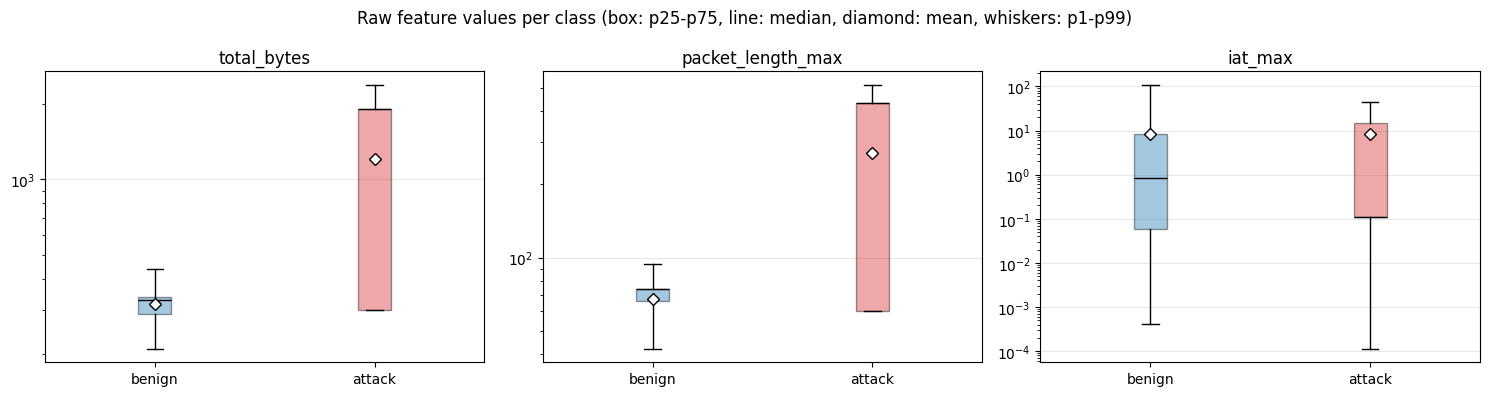

In [5]:
# Per-class statistics of the three features (raw values, all loaded rows).
attack_used = attack_raw[~attack_raw["label"].isin(ATTACK_DROP_LABELS)]
stats = pd.concat({
    "benign": benign_raw[FEATURES].describe(percentiles=[0.01, 0.5, 0.99]).T,
    "attack": attack_used[FEATURES].describe(percentiles=[0.01, 0.5, 0.99]).T,
}, names=["class", "feature"]).swaplevel().sort_index()
stats.to_csv(RESULTS_DIR / "feature_stats.csv")
with pd.option_context("display.float_format", "{:.6g}".format):
    display(stats)

fig, axes = plt.subplots(1, len(FEATURES), figsize=(5 * len(FEATURES), 4))
for ax, feat in zip(axes, FEATURES):
    data = [benign_raw[feat], attack_used[feat]]
    box = ax.boxplot(data, whis=(1, 99), showfliers=False, showmeans=True, patch_artist=True,
                     medianprops={"color": "black"},
                     meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
    for patch, color in zip(box["boxes"], CLASS_COLORS.values()):
        patch.set(facecolor=color, alpha=0.4)
    ax.set_xticks([1, 2], list(CLASS_COLORS))
    if (pd.concat(data) > 0).all():
        ax.set_yscale("log")
    else:                                       # zeros present (e.g. iat_max = 0): log scale starting at 0
        ax.set_yscale("symlog", linthresh=1e-6)
        ax.set_ylim(bottom=0)
    ax.set_title(feat)
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("Raw feature values per class (box: p25-p75, line: median, diamond: mean, whiskers: p1-p99)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "feature_boxplots.png", dpi=150)
plt.show()

**Reading the statistics.** Benign `packet_length_max` never exceeds 96 bytes (the MAWI snaplen) while attack
flows go up to 1514, so the two size features separate the classes very well *in this data*. `iat_max` overlaps
strongly between the classes. Because the features are raw, a 1-byte difference counts as much as a 1-second
difference in the KNN distance, so the size features dominate the decision and `iat_max` mostly matters for
flows with similar sizes.

## 5. Clean, balance, and split

1. **Drop non-attack rows from the attack file**: CICDDoS2019 `BENIGN` rows (the benign class comes from MAWI
   only) and `unknown` rows (no label match).
2. **Drop exact duplicates of the 3-feature vector within each class.** Floods produce many identical vectors;
   if the same vector is in train and test, KNN finds it at distance 0 and the score is inflated.
3. **Balance**: random `SAMPLES_PER_CLASS` flows per class, so accuracy and F1 are not driven by class size.
4. **Split 70/30**, stratified by attack type so every type is in both splits.

In [6]:
attack = attack_raw[~attack_raw["label"].isin(ATTACK_DROP_LABELS)].rename(columns={"label": "attack_type"})
benign = benign_raw.rename(columns={"label": "attack_type"}).assign(attack_type="Benign")
attack["y"], benign["y"] = 1, 0

summary = {"loaded": (len(attack_raw), len(benign_raw)), "after dropping labels": (len(attack), len(benign))}
attack = attack.drop_duplicates(subset=FEATURES)
benign = benign.drop_duplicates(subset=FEATURES)
summary["after dedup"] = (len(attack), len(benign))

in_both = attack[FEATURES].merge(benign[FEATURES], how="inner")
print(f"3-feature vectors present in both classes (cannot be separated by any model): {len(in_both):,}")

n_per_class = min(SAMPLES_PER_CLASS, len(attack), len(benign))
data = pd.concat([attack.sample(n=n_per_class, random_state=RANDOM_STATE),
                  benign.sample(n=n_per_class, random_state=RANDOM_STATE)], ignore_index=True)
summary["balanced sample"] = (n_per_class, n_per_class)

# Attack types with < 2 rows cannot be stratified; group them so the split still works.
type_counts = data["attack_type"].map(data["attack_type"].value_counts())
strata = data["attack_type"].where(type_counts >= 2, "rare")
train_df, test_df = train_test_split(data, test_size=TEST_SIZE, stratify=strata, random_state=RANDOM_STATE)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
summary["train"] = (int(train_df.y.sum()), int((train_df.y == 0).sum()))
summary["test"] = (int(test_df.y.sum()), int((test_df.y == 0).sum()))

display(pd.DataFrame(summary, index=["attack", "benign"]).T)
pd.DataFrame({"train": train_df["attack_type"].value_counts(), "test": test_df["attack_type"].value_counts()})

3-feature vectors present in both classes (cannot be separated by any model): 5


,attack,benign
loaded,1368876,1820701
after dropping labels,1339986,1820701
after dedup,666409,1229280
balanced sample,500000,500000
train,350000,350000
test,150000,150000


,train,test
attack_type,,
Benign,350000,150000
Syn,302397,129599
UDP,46840,20075
NetBIOS,333,142
LDAP,186,79
MSSQL,139,60
UDPLag,54,23
Portmap,51,22


## 6. Visualize the training data

Random 5,000 training flows per class: the three feature pairs in 2D, and all three features in 3D.
Axes are `log10(value)` because the values span several orders of magnitude (`iat_max = 0` is drawn at −7).

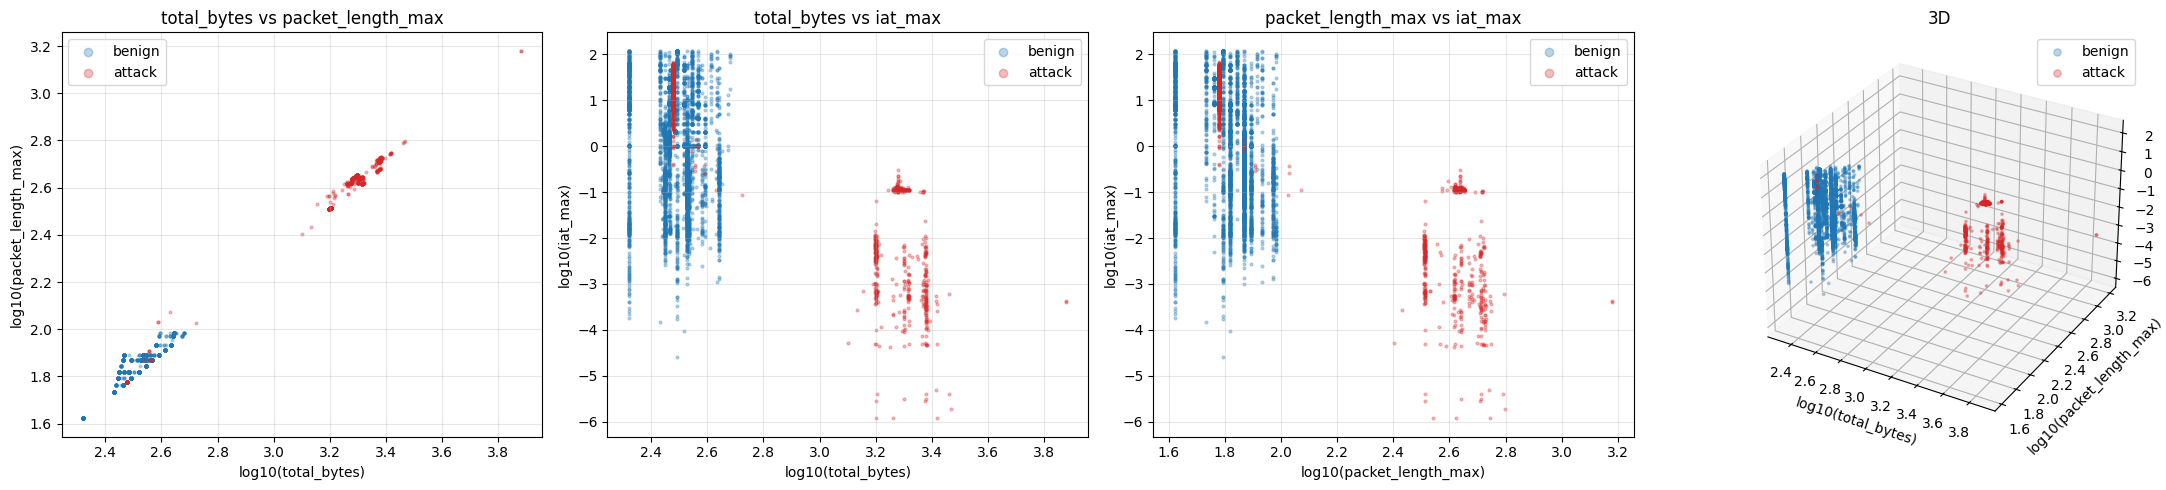

In [7]:
sample = pd.concat([train_df[train_df.y == y].sample(n=5_000, random_state=RANDOM_STATE) for y in (0, 1)])
log = lambda s: np.log10(s.clip(lower=1e-7))

fig = plt.figure(figsize=(22, 5))
for i, (fx, fy) in enumerate(combinations(FEATURES, 2), start=1):
    ax = fig.add_subplot(1, 4, i)
    for y, (name, color) in enumerate(CLASS_COLORS.items()):
        s = sample[sample.y == y]
        ax.scatter(log(s[fx]), log(s[fy]), s=4, alpha=0.3, color=color, label=name)
    ax.set(xlabel=f"log10({fx})", ylabel=f"log10({fy})", title=f"{fx} vs {fy}")
    ax.grid(alpha=0.3)
    ax.legend(markerscale=3)

ax = fig.add_subplot(1, 4, 4, projection="3d")
for y, (name, color) in enumerate(CLASS_COLORS.items()):
    s = sample[sample.y == y]
    ax.scatter(log(s[FEATURES[0]]), log(s[FEATURES[1]]), log(s[FEATURES[2]]), s=3, alpha=0.3, color=color, label=name)
ax.set(xlabel=f"log10({FEATURES[0]})", ylabel=f"log10({FEATURES[1]})", zlabel=f"log10({FEATURES[2]})", title="3D")
ax.legend(markerscale=3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_scatter.png", dpi=150)
plt.show()

## 7. Train and test KNN for every K

For each K: fit `KNeighborsClassifier(n_neighbors=K)` on the raw training features (Euclidean distance, each of
the K nearest training flows votes with weight 1), predict the test split, and record the metrics.

* **precision**: of the flows flagged as attack, the share that really are attacks.
* **recall** (detection rate): of the attack flows, the share that are flagged.
* **FPR** (false-positive rate): of the benign flows, the share wrongly flagged. In real traffic most flows are
  benign, so a small FPR still means many false alarms; this is the metric to watch for deployment.
* **F1**: balance of precision and recall. **ROC-AUC** uses the attack-vote fraction as a score.

In [8]:
X_train, y_train = train_df[FEATURES].to_numpy(), train_df["y"].to_numpy()
X_test, y_test = test_df[FEATURES].to_numpy(), test_df["y"].to_numpy()

models, predictions, results = {}, {}, []
for k in K_VALUES:
    t0 = time.time()
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(X_train, y_train)
    fit_s = time.time() - t0

    t0 = time.time()
    score = model.predict_proba(X_test)[:, 1]          # fraction of the k neighbors that are attacks
    predict_s = time.time() - t0
    y_pred = (score > 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    models[k], predictions[k] = model, y_pred
    results.append({
        "k": k, "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred), "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred), "roc_auc": roc_auc_score(y_test, score),
        "fpr": fp / (fp + tn), "fnr": fn / (fn + tp), "tp": tp, "fp": fp, "tn": tn, "fn": fn,
        "predict_us_per_flow": 1e6 * predict_s / len(X_test),
    })
    print(f"k={k:>2}  F1={results[-1]['f1']:.5f}  FPR={results[-1]['fpr']:.5f}  "
          f"fit={fit_s:.1f}s  predict={predict_s:.1f}s")

results_df = pd.DataFrame(results)
results_df.to_csv(RESULTS_DIR / "knn_results.csv", index=False)

k= 1  F1=0.99989  FPR=0.00010  fit=0.5s  predict=7.0s
k= 3  F1=0.99987  FPR=0.00012  fit=0.6s  predict=7.5s
k= 5  F1=0.99987  FPR=0.00013  fit=0.5s  predict=7.5s
k= 7  F1=0.99987  FPR=0.00012  fit=0.5s  predict=7.9s
k= 9  F1=0.99986  FPR=0.00012  fit=0.5s  predict=8.5s
k=11  F1=0.99984  FPR=0.00012  fit=0.5s  predict=9.0s
k=15  F1=0.99983  FPR=0.00012  fit=0.5s  predict=9.6s


## 8. Compare the K values

,accuracy,precision,recall,f1,roc_auc,fpr,fnr,fp,fn,predict_us_per_flow
k,,,,,,,,,,
1,0.99989,0.99990,0.99989,0.99989,0.99989,0.00010,0.00011,15,17,23.36507
3,0.99987,0.99988,0.99987,0.99987,0.99995,0.00012,0.00013,18,20,24.95277
5,0.99987,0.99987,0.99986,0.99987,0.99996,0.00013,0.00014,19,21,24.94781
7,0.99987,0.99988,0.99986,0.99987,0.99996,0.00012,0.00014,18,21,26.29168
9,0.99986,0.99988,0.99983,0.99986,0.99996,0.00012,0.00017,18,25,28.16833
11,0.99984,0.99988,0.99980,0.99984,0.99996,0.00012,0.00020,18,30,29.84092
15,0.99983,0.99988,0.99978,0.99983,0.99996,0.00012,0.00022,18,33,31.84064


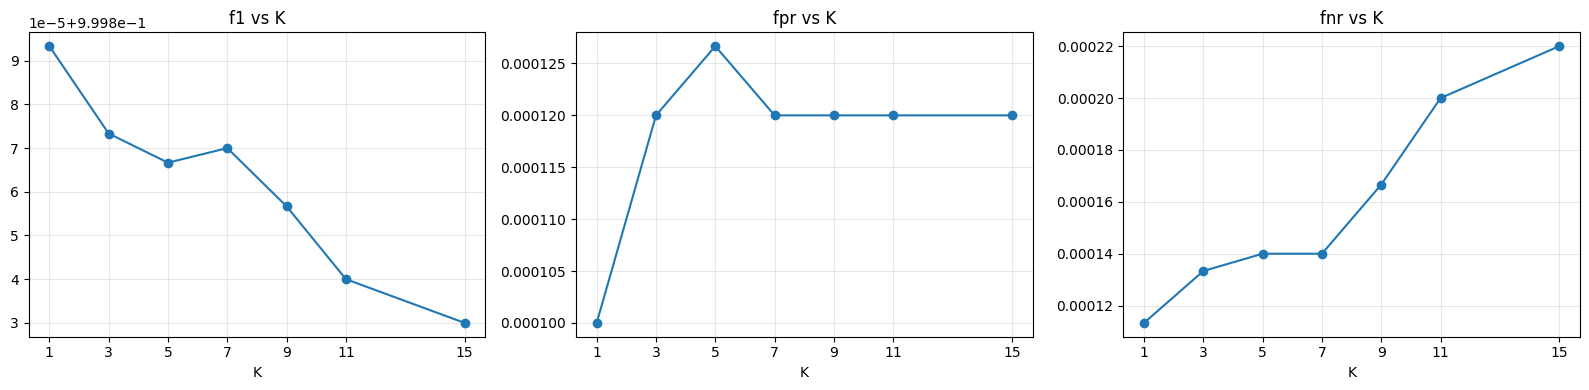

In [9]:
with pd.option_context("display.float_format", "{:.5f}".format):
    display(results_df.set_index("k")[["accuracy", "precision", "recall", "f1", "roc_auc", "fpr", "fnr",
                                      "fp", "fn", "predict_us_per_flow"]])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["f1", "fpr", "fnr"]):
    ax.plot(results_df["k"], results_df[metric], marker="o")
    ax.set(title=f"{metric} vs K", xlabel="K", xticks=K_VALUES)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "metrics_vs_k.png", dpi=150)
plt.show()

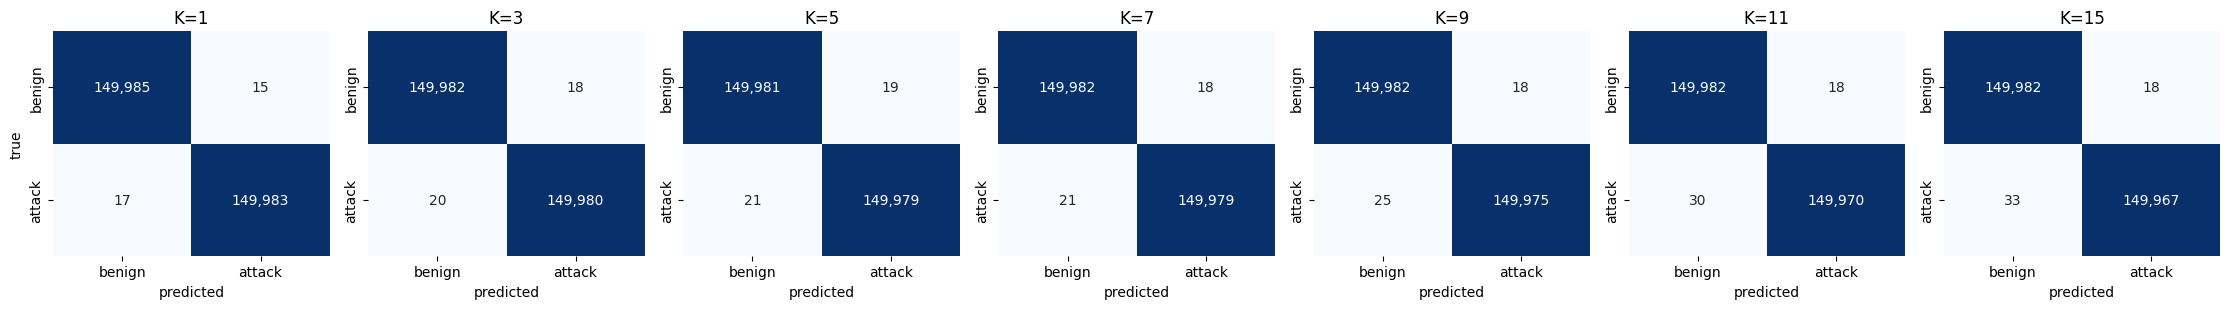

,test_rows,K=1,K=3,K=5,K=7,K=9,K=11,K=15
attack_type,,,,,,,,
Benign,150000,0.9999,0.9999,0.9999,0.9999,0.9999,0.9999,0.9999
LDAP,79,1.0000,1.0000,1.0000,1.0000,1.0000,0.9873,0.9873
MSSQL,60,0.9667,0.9667,0.9667,0.9667,0.9667,0.9667,0.9667
NetBIOS,142,1.0000,1.0000,1.0000,1.0000,1.0000,0.9718,0.9718
Portmap,22,0.9091,0.8636,0.8636,0.8636,0.8636,0.8636,0.8636
Syn,129599,0.9999,0.9999,0.9999,0.9999,0.9998,0.9998,0.9998
UDP,20075,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
UDPLag,23,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


In [10]:
# Confusion matrix for every K (rows: true class, columns: predicted class).
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(3.2 * len(K_VALUES), 3.2))
for ax, k in zip(axes, K_VALUES):
    cm = confusion_matrix(y_test, predictions[k], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=list(CLASS_COLORS), yticklabels=list(CLASS_COLORS))
    ax.set(title=f"K={k}", xlabel="predicted", ylabel="true" if k == K_VALUES[0] else "")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150)
plt.show()

# Share of each traffic type classified correctly, for every K.
correct = pd.DataFrame({k: (predictions[k] == y_test) for k in K_VALUES})
per_type = correct.groupby(test_df["attack_type"]).mean()
per_type.insert(0, "test_rows", test_df["attack_type"].value_counts())
per_type.to_csv(RESULTS_DIR / "correct_rate_per_type.csv")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(per_type.rename(columns=lambda c: f"K={c}" if isinstance(c, int) else c))

## 9. Choose and save the best model

**Rule for choosing K:** highest test **F1**. K values within `F1_TOLERANCE` (0.0001, about 30 flows on the full test
split) of the best are treated as equal; among those, pick the lowest test false-positive rate, then the smallest K
(fewer neighbors to sort in hardware).

**Saved model bundle**: one folder, `models/knn_n5_raw/knn_n5_raw_k<K>/`, with everything needed to reuse the model
in another notebook:

| File | Contents |
|---|---|
| `model.joblib` | the fitted `KNeighborsClassifier` (raw features, no scaler) |
| `metadata.json` | feature names **in input order**, units, N, K, label meaning, how features are extracted, training settings, test metrics, library versions |
| `training_points.csv` | the training flows (`total_bytes, packet_length_max, iat_max, label`). For KNN these points *are* the model: this is what the hardware stores, and the model can be rebuilt from it with any K |
| `test_split.csv` | the held-out test flows (5-tuple, features, attack type, label), to re-check results |
| `results_all_k.csv` | test metrics for every K |

In [11]:
import json
import platform
from datetime import datetime, timezone

import sklearn

F1_TOLERANCE = 0.0001

best_f1 = results_df["f1"].max()
candidates = results_df[results_df["f1"] >= best_f1 - F1_TOLERANCE]
best = candidates.sort_values(["fpr", "k"]).iloc[0]
best_k = int(best["k"])

with pd.option_context("display.float_format", "{:.5f}".format):
    display(candidates.set_index("k")[["f1", "precision", "recall", "fpr", "fnr"]])
print(f"Best model: K = {best_k}   F1 = {best.f1:.5f}   recall = {best.recall:.5f}   FPR = {best.fpr:.5f}")

# ---- Save the model bundle
BUNDLE_DIR = MODELS_DIR / f"knn_n{N}_raw_k{best_k}"
BUNDLE_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(models[best_k], BUNDLE_DIR / "model.joblib")
pd.DataFrame(X_train, columns=FEATURES).assign(label=y_train).to_csv(BUNDLE_DIR / "training_points.csv", index=False)
test_df[ID_COLUMNS + FEATURES + ["attack_type", "y"]].to_csv(BUNDLE_DIR / "test_split.csv", index=False)
results_df.to_csv(BUNDLE_DIR / "results_all_k.csv", index=False)

metadata = {
    "model": "sklearn.neighbors.KNeighborsClassifier",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "k": best_k,
    "weights": "uniform",
    "metric": "euclidean",
    "features": FEATURES,                      # input column order for model.predict
    "feature_units": {"total_bytes": "bytes", "packet_length_max": "bytes", "iat_max": "seconds"},
    "scaling": "raw (no preprocessing)",
    "labels": {"0": "benign", "1": "attack"},
    "decision": "attack if more than half of the k nearest training flows are attacks (predict_proba[:, 1] > 0.5)",
    "flow": {
        "N_packets": N,
        "key": "directional 5-tuple (src_ip, dst_ip, src_port, dst_port, protocol)",
        "packet_length": "frame length in bytes including the 14-byte Ethernet header, no FCS",
        "timestamp": "seconds",
        "total_bytes": "sum of packet_length over the first N packets",
        "packet_length_max": "max of packet_length over the first N packets",
        "iat_max": "max of (ts[i] - ts[i-1]) over the first N packets, 0 if N == 1",
        "idle_timeout_seconds": 120,
    },
    "training": {
        "attack_file": str(FEATURES_DIR / f"attack_features_n{N}.csv"),
        "benign_file": str(FEATURES_DIR / f"benign_features_n{N}.csv"),
        "attack_dropped_labels": sorted(ATTACK_DROP_LABELS),
        "deduplicated_on": FEATURES,
        "samples_per_class": int(n_per_class),
        "test_size": TEST_SIZE,
        "random_state": RANDOM_STATE,
        "train_rows": {"attack": int(y_train.sum()), "benign": int((y_train == 0).sum())},
        "test_rows": {"attack": int(y_test.sum()), "benign": int((y_test == 0).sum())},
        "k_values_compared": K_VALUES,
        "selection_rule": f"max test F1 (tolerance {F1_TOLERANCE}), then min test FPR, then smallest k",
    },
    "test_metrics": {m: float(best[m]) for m in ["accuracy", "precision", "recall", "f1", "roc_auc", "fpr", "fnr"]},
    "known_limitation": "Benign training data (MAWI) captured with snaplen 96: benign packet lengths are <= 96 bytes. "
                        "Test metrics are not expected to hold on live traffic until benign data is re-extracted "
                        "with the IP total length.",
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
(BUNDLE_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))

print(f"\nSaved model bundle: {BUNDLE_DIR}")
for f in sorted(BUNDLE_DIR.iterdir()):
    print(f"  {f.name:<22} {f.stat().st_size / 1e6:8.1f} MB")

,f1,precision,recall,fpr,fnr
k,,,,,
1,0.99989,0.99990,0.99989,0.00010,0.00011
3,0.99987,0.99988,0.99987,0.00012,0.00013
5,0.99987,0.99987,0.99986,0.00013,0.00014
7,0.99987,0.99988,0.99986,0.00012,0.00014
9,0.99986,0.99988,0.99983,0.00012,0.00017
11,0.99984,0.99988,0.99980,0.00012,0.00020
15,0.99983,0.99988,0.99978,0.00012,0.00022


Best model: K = 1   F1 = 0.99989   recall = 0.99989   FPR = 0.00010

Saved model bundle: /home/ubuntu/DDoS_ML/offline/models/knn_n5_raw/knn_n5_raw_k1
  metadata.json               0.0 MB
  model.joblib               47.4 MB
  results_all_k.csv           0.0 MB
  test_split.csv             22.8 MB
  training_points.csv        22.2 MB


## 10. Check that the saved model reloads

Load the bundle from disk exactly as another notebook would, and check that it gives the same predictions as the
model trained above. Also rebuild the model from `training_points.csv` alone (what the hardware will use) and
check that it matches too.

In [12]:
loaded_meta = json.loads((BUNDLE_DIR / "metadata.json").read_text())
loaded_model = joblib.load(BUNDLE_DIR / "model.joblib")
points = pd.read_csv(BUNDLE_DIR / "training_points.csv")
saved_test = pd.read_csv(BUNDLE_DIR / "test_split.csv")

check_X = saved_test[loaded_meta["features"]].to_numpy()
reloaded_pred = loaded_model.predict(check_X)
rebuilt_model = KNeighborsClassifier(n_neighbors=loaded_meta["k"]).fit(
    points[loaded_meta["features"]].to_numpy(), points["label"].to_numpy())
subset = slice(0, 20_000)                                    # rebuilding is checked on a subset to keep it fast

checks = {
    "metadata features == FEATURES": loaded_meta["features"] == FEATURES,
    "reloaded model: same predictions on the full test split": bool((reloaded_pred == predictions[best_k]).all()),
    "reloaded model: same F1 as Section 7": bool(np.isclose(f1_score(saved_test["y"], reloaded_pred), best.f1)),
    "rebuilt from training_points.csv: same predictions": bool(
        (rebuilt_model.predict(check_X[subset]) == reloaded_pred[subset]).all()),
}
for name, ok in checks.items():
    print(f"[{'OK' if ok else 'FAIL'}] {name}")
assert all(checks.values())

[OK] metadata features == FEATURES
[OK] reloaded model: same predictions on the full test split
[OK] reloaded model: same F1 as Section 7
[OK] rebuilt from training_points.csv: same predictions


### Using the model in another notebook

The new data must be one row per flow with the three features computed as in Section 2 (first 5 packets,
lengths in bytes including the Ethernet header, times in seconds). If it also has a `y` column (1 = attack,
0 = benign), it can be scored.

```python
import json, joblib
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

BUNDLE_DIR = Path("/home/ubuntu/DDoS_ML/offline/models/knn_n5_raw/knn_n5_raw_k1")   # k from Section 9
meta  = json.loads((BUNDLE_DIR / "metadata.json").read_text())
model = joblib.load(BUNDLE_DIR / "model.joblib")
# If joblib fails (e.g. a different scikit-learn version), rebuild the same model from the training points:
#   from sklearn.neighbors import KNeighborsClassifier
#   pts = pd.read_csv(BUNDLE_DIR / "training_points.csv")
#   model = KNeighborsClassifier(n_neighbors=meta["k"]).fit(pts[meta["features"]].to_numpy(), pts["label"])

new_flows = pd.read_csv("unseen_flows.csv")                    # your data
X = new_flows[meta["features"]].to_numpy()                     # same columns, same order, raw values
new_flows["pred"] = model.predict(X)                           # 1 = attack, 0 = benign
new_flows["attack_score"] = model.predict_proba(X)[:, 1]       # share of the k neighbors that are attacks

if "y" in new_flows:
    print(confusion_matrix(new_flows["y"], new_flows["pred"], labels=[0, 1]))
    print(classification_report(new_flows["y"], new_flows["pred"], target_names=["benign", "attack"], digits=4))
```

### Conclusion

* **Which K:** printed in Section 9, chosen by test F1 (then test FPR, then smallest K). On this data all K values
  score within about a thousandth of each other, so K matters much less than the data; a small K is also the
  cheapest to implement in hardware.
* **Feature extraction in hardware** needs 5 registers per flow and only `+`, `-` and `max` per packet (Section 2),
  with lengths in bytes (Ethernet frame) and times in seconds, exactly as in training.
* **The model is saved as a bundle** (Section 9) and verified to reload (Section 10). Use the snippet above to test
  it on unseen data in another notebook.
* **Before trusting the model on live traffic**, test it on data from a different capture than the training data.
  The benign training data is capped at 96 bytes per packet (MAWI snaplen), so real benign flows with larger packets
  are likely to be flagged as attacks. Re-extract the benign data with the IP total length and re-run this notebook.
* **Model size:** a KNN keeps every training point. `training_points.csv` is what the hardware must store and
  search; reducing it (for example to per-class cluster centroids) is the next step if it does not fit.